# FACECAST

In this notebook we are going to build a network that takes a 16×16 picture of a face and produces a 128×128 picture of it. That is 8× upscaling per side, so the output has 64 times more pixels than the input. Most of the output cannot be *recovered* from the input, it has to be *invented* in a plausible way, which is why the task is called **face hallucination**. We are going to use the CelebA dataset and you can learn more about it [here](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html). This notebook consists of the following steps:
* Environment setup
* Dataset download
* Data preprocessing
* Degradation (making the low-resolution inputs)
* Baselines and metrics
* Building the generator network
* Training with the pixel loss (stage 1)
* Fine-tuning with the perceptual and the adversarial loss (stage 2)
* Modification: relativistic loss and U-Net discriminator
* Evaluation
* Demo on your own image

### Step 0: Environment Setup

The dependencies are listed in `pyproject.toml` and managed by [uv](https://docs.astral.sh/uv/). Run `uv sync` once in the project folder, it creates the `.venv` environment with everything installed. Then select `.venv` as the kernel of this notebook.

Note that `pip` is not available in a uv environment, so `%pip install` does not work here. To add a new package, use `uv add <package>` in the terminal.

In [1]:
import os
# Folder for the downloads (has to be set before datasets is imported)
data_dir = os.path.abspath('data')
os.environ['HF_HOME'] = data_dir
os.environ['TORCH_HOME'] = os.path.join(data_dir, 'torch')

import copy
import random
import warnings
from time import time
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import datasets
import lpips
from datasets import load_dataset
from PIL import Image
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seed for reproducibility (python, numpy and torch)
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

# Use the GPU if there is one
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('PyTorch:     ', torch.__version__)
print('Torchvision: ', torchvision.__version__)
print('Datasets:    ', datasets.__version__)
print('Data folder: ', data_dir)
print('Device:      ', device, '-', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'no GPU found')

PyTorch:      2.11.0+cu128
Torchvision:  0.26.0+cu128
Datasets:     5.2.0
Data folder:  /home/anton/PycharmProjects/facecast/data
Device:       cuda - NVIDIA GeForce RTX 5090


### Step 1: Dataset Download

Download the CelebA dataset (aligned and cropped faces) from Hugging Face. Everything we download goes to the `data` folder (we pointed `HF_HOME` to it in the previous step), which is not tracked by git.

The download is about 11.7 GB and the prepared copy takes the same again, so you need about 24 GB of free space and the first run takes a while. The next runs find the files in `data` and load them right away.

In [2]:
# Download the dataset (or load it from the data folder if it is already there)
dataset = load_dataset('flwrlabs/celeba')

# The dataset comes with the official train / validation / test split
train_set, val_set, test_set = dataset['train'], dataset['valid'], dataset['test']

print('Train set:      ', len(train_set), 'samples')
print('Validation set: ', len(val_set), 'samples')
print('Test set:       ', len(test_set), 'samples')

Train set:       162770 samples
Validation set:  19867 samples
Test set:        19962 samples


Make a quick inspection to check that the download is fine.

Columns:     42 - ['image', 'celeb_id', '5_o_Clock_Shadow', 'Arched_Eyebrows'] ...
Image size:  (178, 218) RGB
Identities:  8192 in the train set


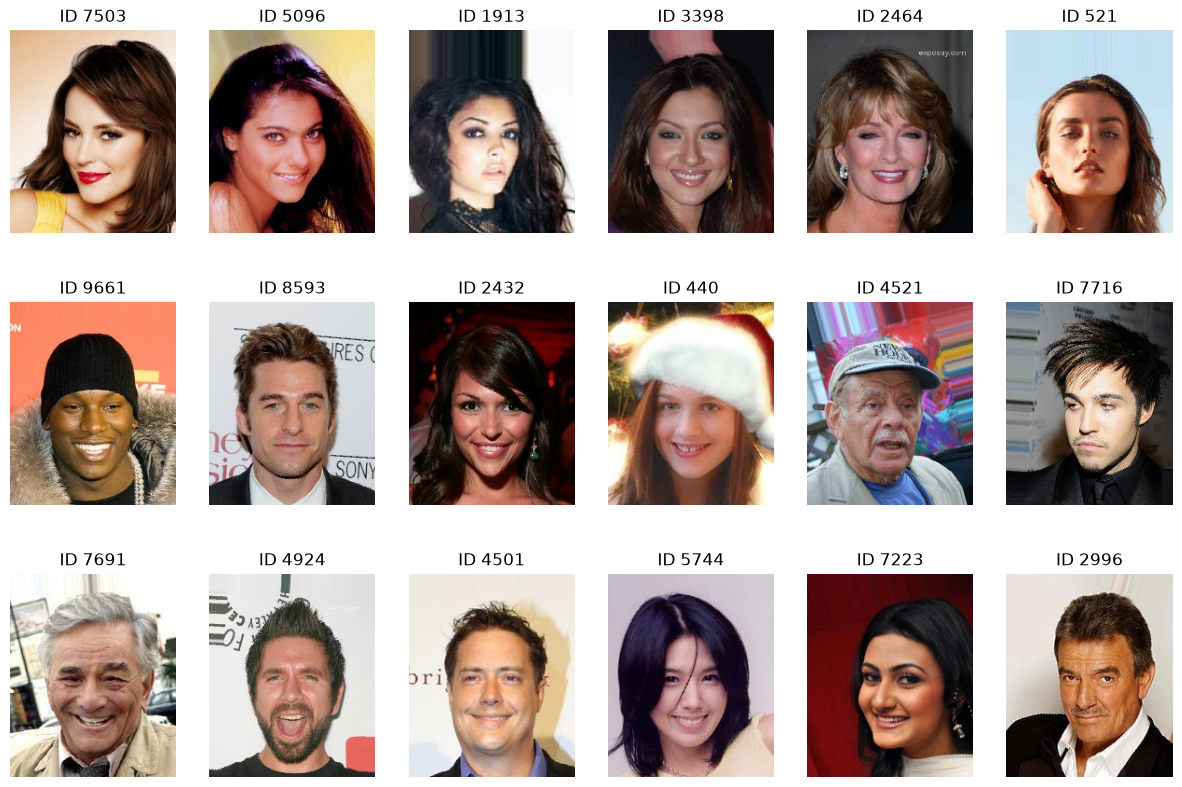

In [3]:
# Every sample is an image, the ID of the person and 40 binary attributes
sample = train_set[0]
print('Columns:    ', len(train_set.column_names), '-', train_set.column_names[:4], '...')
print('Image size: ', sample['image'].size, sample['image'].mode)
print('Identities: ', len(set(train_set['celeb_id'])), 'in the train set')

# Visualize random samples (as a plot with 3x6 samples)
for ii in range(18):
    plt.subplot(3,6,ii+1)
    # Pick a random sample
    idx = np.random.randint(0, len(train_set))
    # Show the image and the ID of the person
    plt.imshow(train_set[idx]['image'])
    plt.title('ID ' + str(train_set[idx]['celeb_id']))
    plt.axis('off')

### Step 2: Data Preprocessing

The CelebA images are 178×218, but we want square 128×128 faces as the high-resolution (HR) targets. So every image is center-cropped to a square (178×178) and resized to 128×128.

Decoding 160k images takes a few minutes, and we do not want to repeat it in every epoch. Therefore, the preprocessed faces are stored once in the `data` folder as plain `uint8` arrays (about 8 GB for the train set). The next runs just open these files. They are opened as memory maps, so only the faces we actually ask for are read from the disk.

We use the whole train set, the first 2000 faces of the validation set and 2000 random faces of the test set. The test split is sorted by the person, so its first 2000 faces would show 91 people only, while a random subset covers almost all of them.

In [4]:
# Dataset params
hr_size = 128     # size of the high-resolution face
num_val = 2000    # faces used for the validation during training
num_test = 2000   # faces used for the final evaluation

def preprocess(img):
    # Center-crop the image to a square
    img = img.convert('RGB')
    w, h = img.size
    s = min(w, h)
    left, top = (w - s)//2, (h - s)//2
    img = img.crop((left, top, left + s, top + s))
    # Resize it to the HR size
    img = img.resize((hr_size, hr_size), Image.LANCZOS)
    return np.asarray(img, dtype=np.uint8)

def load_split(split, name):
    path = os.path.join(data_dir, 'celeba_%s_%d_%d.npy' % (name, hr_size, len(split)))
    if not os.path.exists(path):
        # Preprocess the images one by one and write them straight to the disk
        tmp = path + '.tmp'
        arr = np.lib.format.open_memmap(tmp, mode='w+', dtype=np.uint8, shape=(len(split), hr_size, hr_size, 3))
        for ii, sample in enumerate(tqdm(split, desc='Preprocessing ' + name)):
            arr[ii] = preprocess(sample['image'])
        arr.flush()
        del arr
        # Rename the file at the very end, so an interrupted run never leaves a half-written file
        os.replace(tmp, path)
    # Open the file as a read-only memory map
    return np.load(path, mmap_mode='r')

# Preprocess the splits (or open them from the data folder if they are already there)
hr_train = load_split(train_set.select_columns(['image']), 'train')
hr_val = load_split(val_set.select_columns(['image']).select(range(num_val)), 'val')
# The test split is sorted by the person, so we take a random subset of it (with its own fixed seed)
test_idx = np.sort(np.random.default_rng(1234).choice(len(test_set), num_test, replace=False))
hr_test = load_split(test_set.select_columns(['image']).select(test_idx), 'test_random')

print('Train set:      ', hr_train.shape, hr_train.dtype)
print('Validation set: ', hr_val.shape)
print('Test set:       ', hr_test.shape)
print('Range:          ', hr_test.min(), '-', hr_test.max())
print('Test identities:', len(set(test_set.select(test_idx)['celeb_id'])), 'out of', len(set(test_set['celeb_id'])))

Train set:       (162770, 128, 128, 3) uint8
Validation set:  (2000, 128, 128, 3)
Test set:        (2000, 128, 128, 3)
Range:           0 - 255
Test identities: 821 out of 1000


Compare a few original images (top row) with their preprocessed versions (bottom row).

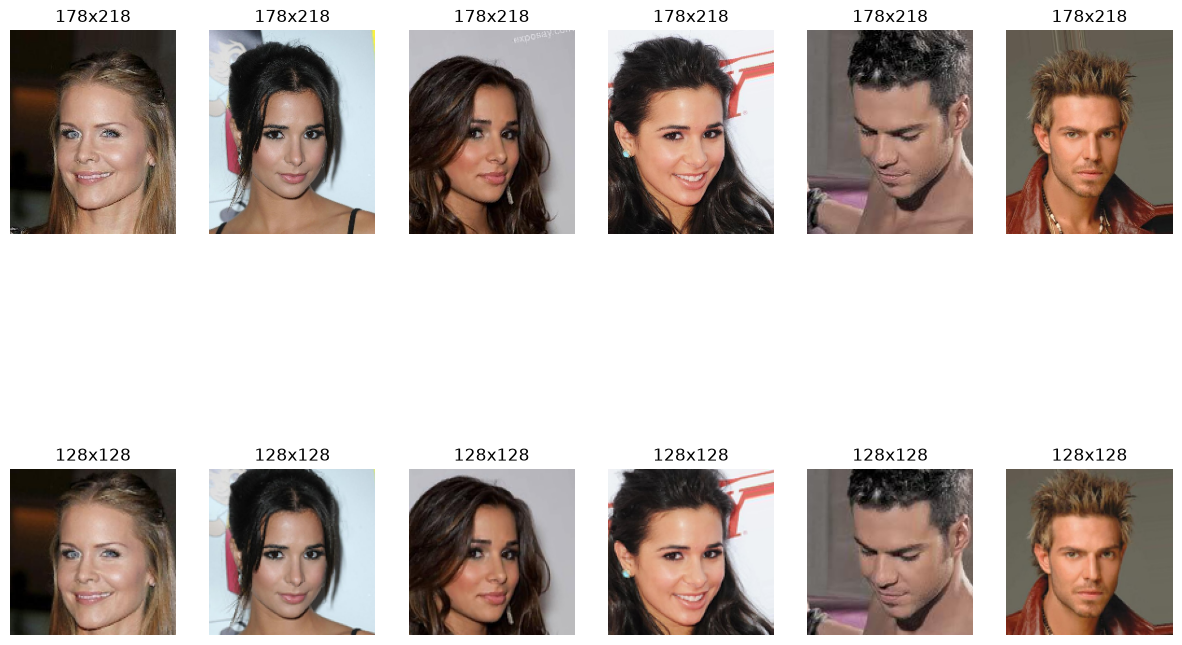

In [5]:
# Show the first test samples before and after the preprocessing
for ii in range(6):
    img = test_set[int(test_idx[ii])]['image']
    plt.subplot(2,6,ii+1), plt.imshow(img)
    plt.title('%dx%d' % img.size), plt.axis('off')
    plt.subplot(2,6,ii+7), plt.imshow(hr_test[ii])
    plt.title('%dx%d' % hr_test[ii].shape[:2]), plt.axis('off')

### Step 3: Degradation

The network needs pairs of low-resolution (LR) inputs and HR targets. We only have the HR faces, so we make the LR inputs ourselves: every 8×8 block of pixels is averaged to a single pixel, which turns a 128×128 face into a 16×16 one. The result is rounded to 8 bits, because that is what a real image file would contain.

The LR images are not stored. It is cheaper to compute them on the GPU from every HR batch.

We also need two small helpers to move the data between the `uint8` arrays of shape (N, H, W, 3) and the float tensors of shape (N, 3, H, W) in the 0 - 1 range that PyTorch works with.

In [6]:
scale = 8                    # upscaling factor
lr_size = hr_size // scale   # size of the low-resolution face

def to_tensor(u8):
    # (N,H,W,3) uint8 array -> (N,3,H,W) float tensor in 0 - 1 on the device
    return torch.from_numpy(np.array(u8)).to(device).permute(0, 3, 1, 2).float()/255

def to_u8(t):
    # (N,3,H,W) float tensor -> (N,H,W,3) uint8 array
    return (t.float().clamp(0, 1)*255).round().byte().permute(0, 2, 3, 1).cpu().numpy()

def degrade(hr):
    # Average every scale x scale block of pixels
    lr = F.avg_pool2d(hr, scale)
    # Round to 8 bits
    return torch.round(lr*255)/255

hr = to_tensor(hr_test[:6])
lr = degrade(hr)

print('HR batch: ', tuple(hr.shape))
print('LR batch: ', tuple(lr.shape))
print('Pixels:   ', hr_size*hr_size, '->', lr_size*lr_size, '(%dx fewer)' % (scale*scale))

HR batch:  (6, 3, 128, 128)
LR batch:  (6, 3, 16, 16)
Pixels:    16384 -> 256 (64x fewer)


For an integer factor, the block averaging is the same thing as `cv2.resize` with the `INTER_AREA` interpolation. Let's check it, the two results may differ by 1 gray level at most (because of the rounding).

In [7]:
# Degrade the same faces with OpenCV
lr_gpu = to_u8(lr)
lr_cv2 = np.stack([cv2.resize(img, (lr_size, lr_size), interpolation=cv2.INTER_AREA) for img in hr_test[:6]])

diff = np.abs(lr_gpu.astype(int) - lr_cv2.astype(int))
print('Max difference: ', diff.max(), 'gray levels')
print('Pixels equal:   ', '%.1f %%' % (100*np.mean(diff == 0)))

Max difference:  1 gray levels
Pixels equal:    99.3 %


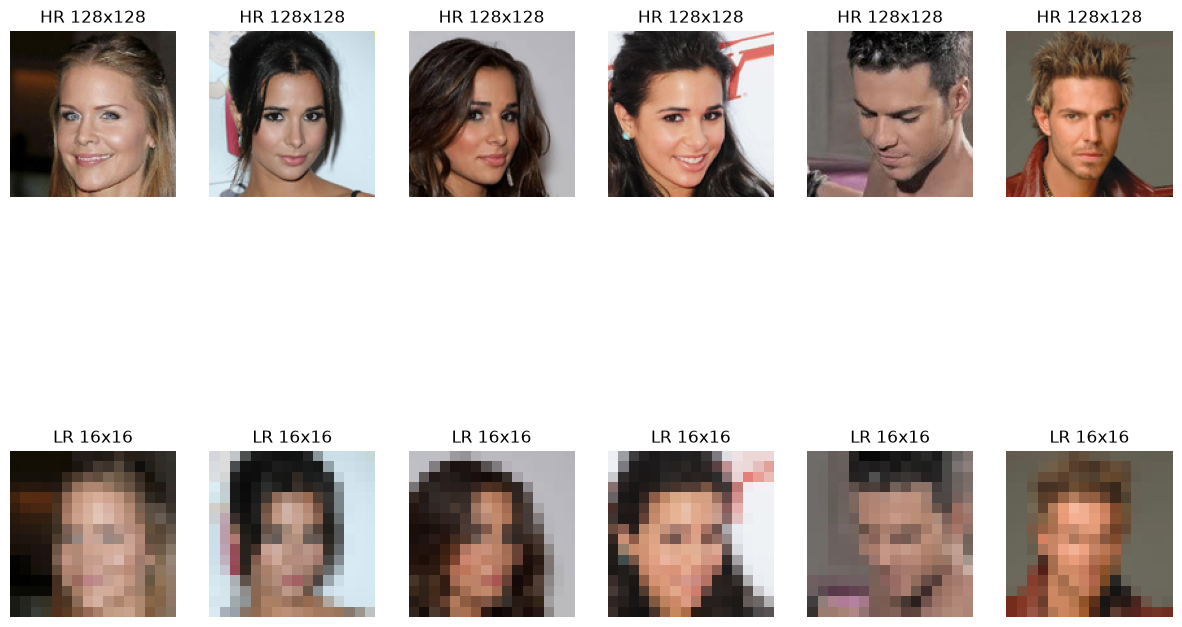

In [8]:
# Show the HR targets (top row) and the LR inputs (bottom row)
for ii in range(6):
    plt.subplot(2,6,ii+1), plt.imshow(hr_test[ii])
    plt.title('HR %dx%d' % (hr_size, hr_size)), plt.axis('off')
    # Show the LR pixels as they are, without smoothing
    plt.subplot(2,6,ii+7), plt.imshow(lr_gpu[ii], interpolation='nearest')
    plt.title('LR %dx%d' % (lr_size, lr_size)), plt.axis('off')

### Step 4: Baselines and Metrics

Before building any network, we need something to compare it with. The baselines are the four interpolation methods of `cv2.resize`:
* Nearest: copies the closest LR pixel, which gives visible blocks
* Bilinear: blends the 2×2 nearest pixels
* Bicubic: blends the 4×4 nearest pixels (the usual reference in the super-resolution papers)
* Lanczos: blends the 8×8 nearest pixels

Note that none of them adds any information, they only smooth between the pixels that are already there.

LR test set:  (2000, 16, 16, 3) uint8


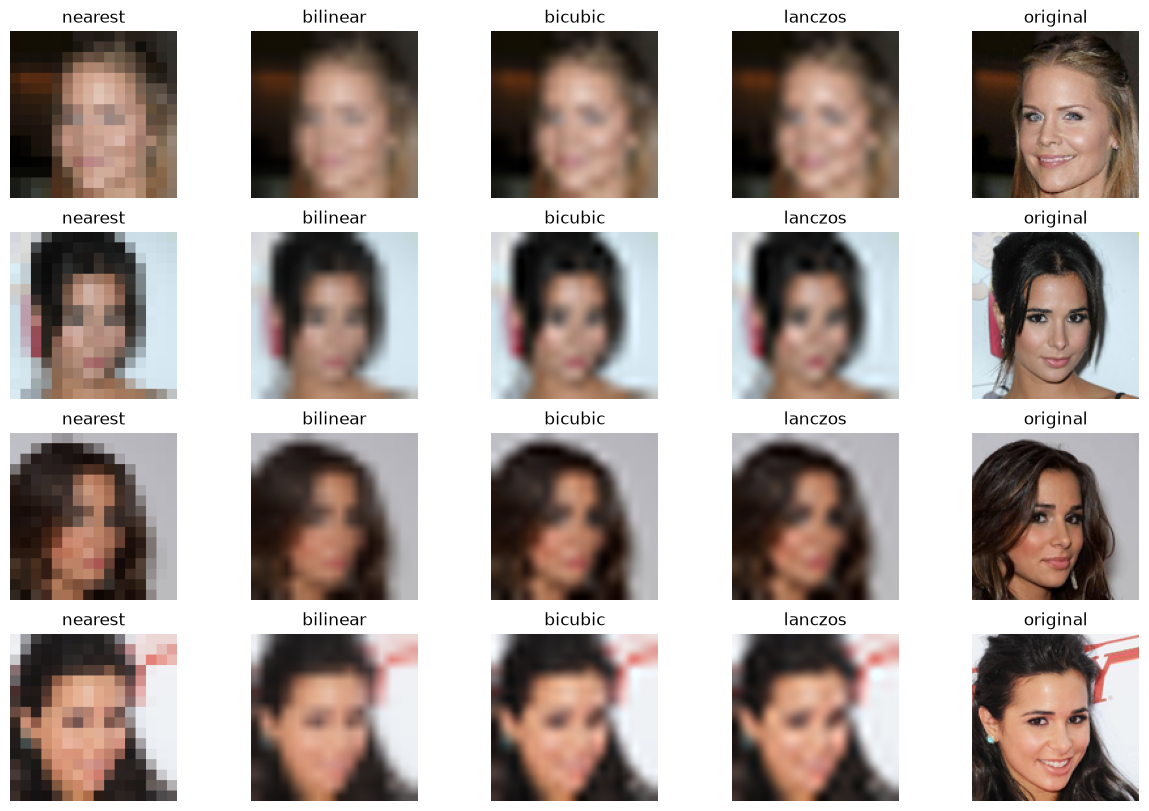

In [9]:
# The interpolation methods of cv2.resize
baselines = {'nearest': cv2.INTER_NEAREST, 'bilinear': cv2.INTER_LINEAR,
             'bicubic': cv2.INTER_CUBIC, 'lanczos': cv2.INTER_LANCZOS4}

def cv2_upscale(lr_u8, interpolation):
    # (N,h,w,3) uint8 array -> (N,H,W,3) uint8 array
    return np.stack([cv2.resize(img, (hr_size, hr_size), interpolation=interpolation) for img in lr_u8])

# Degrade the whole test set (the LR images are tiny, so they fit in the memory easily)
lr_test = np.concatenate([to_u8(degrade(to_tensor(hr_test[ii:ii+100]))) for ii in range(0, len(hr_test), 100)])
print('LR test set: ', lr_test.shape, lr_test.dtype)

# Show what the baselines can recover (one row per face, one column per method)
rows = 4
for ii in range(rows):
    for jj, name in enumerate(baselines):
        plt.subplot(rows,5,ii*5+jj+1), plt.imshow(cv2_upscale(lr_test[ii:ii+1], baselines[name])[0])
        plt.title(name), plt.axis('off')
    plt.subplot(rows,5,ii*5+5), plt.imshow(hr_test[ii])
    plt.title('original'), plt.axis('off')

We are going to use three metrics. All of them compare the upscaled image with the original HR face:
* **PSNR** (in dB, higher is better): the pixel-wise error on a logarithmic scale. +3 dB means half of the mean squared error.
* **SSIM** (0 to 1, higher is better): compares the local brightness, contrast and structure in small windows.
* **LPIPS** (lower is better): the distance between the feature maps of a pretrained network (AlexNet). It is closer to how people judge the similarity of two images.

Each function takes two batches of `uint8` images and returns one value per image.

In [10]:
def psnr(a, b):
    # Mean squared error of each image
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64))**2, axis=(1, 2, 3))
    # The lower limit of the error avoids a division by zero for identical images
    return 10*np.log10(255**2/np.maximum(mse, 1e-10))

def ssim(a, b):
    return np.array([structural_similarity(x, y, channel_axis=2, data_range=255) for x, y in zip(a, b)])

# The LPIPS network (its weights go to the data folder as well)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')    # torchvision complains about the way lpips loads the weights
    lpips_model = lpips.LPIPS(net='alex', verbose=False).to(device).eval()

@torch.no_grad()
def lpips_dist(a, b):
    # LPIPS expects the images in the -1 to 1 range
    dist = [lpips_model(to_tensor(a[ii:ii+100])*2 - 1, to_tensor(b[ii:ii+100])*2 - 1) for ii in range(0, len(a), 100)]
    return torch.cat(dist).flatten().cpu().numpy()

# Sanity check: an image compared with itself and with a noisy copy of itself
img = np.array(hr_test[:1])
noisy = np.clip(img + np.random.normal(0, 10, img.shape), 0, 255).astype(np.uint8)
print('%-10s %10s %8s %8s' % ('', 'PSNR (dB)', 'SSIM', 'LPIPS'))
print('%-10s %10.2f %8.4f %8.4f' % ('identical', psnr(img, img)[0], ssim(img, img)[0], lpips_dist(img, img)[0]))
print('%-10s %10.2f %8.4f %8.4f' % ('noisy', psnr(img, noisy)[0], ssim(img, noisy)[0], lpips_dist(img, noisy)[0]))

            PSNR (dB)     SSIM    LPIPS
identical      148.13   1.0000   0.0000
noisy           28.32   0.7147   0.1296


Now evaluate the baselines on the test set. These are the numbers our network has to beat.

In [11]:
# Compute the metrics of each baseline (averaged over the test set)
hr_test_u8 = np.array(hr_test)
results = {}
for name, interpolation in baselines.items():
    sr = cv2_upscale(lr_test, interpolation)
    results[name] = {'psnr': psnr(sr, hr_test_u8).mean(),
                     'ssim': ssim(sr, hr_test_u8).mean(),
                     'lpips': lpips_dist(sr, hr_test_u8).mean()}

print('%-10s %10s %8s %8s' % ('', 'PSNR (dB)', 'SSIM', 'LPIPS'))
for name, r in results.items():
    print('%-10s %10.2f %8.4f %8.4f' % (name, r['psnr'], r['ssim'], r['lpips']))

            PSNR (dB)     SSIM    LPIPS
nearest         20.05   0.4977   0.5813
bilinear        20.93   0.5623   0.5498
bicubic         21.63   0.5881   0.5636
lanczos         21.71   0.5897   0.5718


The baselines are close to each other: about 20 - 22 dB of PSNR and an SSIM below 0.6. The sharper the interpolation, the better the PSNR and the SSIM (nearest < bilinear < bicubic < Lanczos). But LPIPS tells a different story: bilinear is the best one there, and bicubic and Lanczos are slightly worse, because they add ringing around the edges.

In any case, all four produce a blurry face. They can not do better, the details are simply not in the 16×16 input. Lanczos (21.71 dB) and bicubic (21.63 dB) are the numbers to beat.

### Step 5: Building the Generator

Build the network that turns a 16×16 LR face into a 128×128 one. It is called the generator, because it generates the details that are missing in the input. We are going to use an SRResNet-style CNN that consists of four parts:
* **Head**: one convolution that lifts the 3 color channels to 64 feature channels.
* **Body**: 16 residual blocks (conv - ReLU - conv, added to the input of the block). All of them work at the low 16×16 resolution, which keeps the network fast.
* **Upsampling**: three stages, each of them doubles the resolution (16 → 32 → 64 → 128). A stage is a convolution that produces 4× more channels and a `PixelShuffle` layer that rearranges them into a 2× wider and 2× taller feature map.
* **Tail**: two convolutions that turn the 64 feature channels back into the 3 color channels.

There are two more tricks:
* The bicubic upscale of the input is added to the output. So the network does not have to learn the whole face, only the difference between the bicubic upscale and the real face (the residual).
* The last convolution is initialized with zeros. Therefore, the untrained network outputs exactly the bicubic upscale and the training can only improve on it.

Note that there is no batch normalization, it tends to hurt the pixel-accurate restoration.

In [12]:
num_blocks = 16   # residual blocks in the body
num_feats = 64    # feature channels

class ResBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, 3, padding=1),
        )

    def forward(self, x):
        return x + self.body(x)

class Generator(nn.Module):
    def __init__(self, scale, num_blocks, num_feats):
        super().__init__()
        self.scale = scale
        # Head: color channels -> feature channels
        self.head = nn.Conv2d(3, num_feats, 3, padding=1)
        # Body: residual blocks at the low resolution
        blocks = [ResBlock(num_feats) for _ in range(num_blocks)]
        self.body = nn.Sequential(*blocks, nn.Conv2d(num_feats, num_feats, 3, padding=1))
        # Upsampling: every stage doubles the resolution
        up = []
        for _ in range(int(np.log2(scale))):
            up += [nn.Conv2d(num_feats, 4*num_feats, 3, padding=1), nn.PixelShuffle(2), nn.ReLU(inplace=True)]
        self.up = nn.Sequential(*up)
        # Tail: feature channels -> color channels
        self.tail = nn.Sequential(nn.Conv2d(num_feats, num_feats, 3, padding=1), nn.ReLU(inplace=True),
                                  nn.Conv2d(num_feats, 3, 3, padding=1))
        # Start exactly at the bicubic upscale
        nn.init.zeros_(self.tail[-1].weight)
        nn.init.zeros_(self.tail[-1].bias)

    def forward(self, lr):
        # Bicubic upscale of the input
        base = F.interpolate(lr.float(), scale_factor=self.scale, mode='bicubic', align_corners=False)
        # The network predicts the residual (the input is shifted to the -0.5 to 0.5 range)
        x = self.head(lr - 0.5)
        x = x + self.body(x)
        x = self.tail(self.up(x))
        return x.float() + base

# Build the generator
generator = Generator(scale, num_blocks, num_feats).to(device)

# Show the model
print('%-6s %10s' % ('Part', 'Params'))
for name, part in generator.named_children():
    print('%-6s %10d' % (name, sum(p.numel() for p in part.parameters())))
print('%-6s %10d' % ('total', sum(p.numel() for p in generator.parameters())))

Part       Params
head         1792
body      1218624
up         443136
tail        38659
total     1702211


Check that the network works. We push the LR test faces through the untrained generator and compare the result with the bicubic baseline. Because of the zero initialization, the PSNR should be almost the same.

In [13]:
@torch.no_grad()
def model_upscale(model, lr_u8):
    # (N,h,w,3) uint8 array -> (N,H,W,3) uint8 array
    model.eval()
    sr = [model(to_tensor(lr_u8[ii:ii+100])) for ii in range(0, len(lr_u8), 100)]
    return to_u8(torch.cat(sr))

sr = model_upscale(generator, lr_test)

print('Input:  ', lr_test.shape)
print('Output: ', sr.shape)
print('PSNR of the untrained generator: %.2f dB' % psnr(sr, hr_test_u8).mean())
print('PSNR of the bicubic baseline:    %.2f dB' % results['bicubic']['psnr'])

Input:   (2000, 16, 16, 3)
Output:  (2000, 128, 128, 3)
PSNR of the untrained generator: 21.63 dB
PSNR of the bicubic baseline:    21.63 dB


The generator has 1.7 M parameters and most of them (72 %) are in the body, i.e., in the residual blocks that work at the low resolution. The output has the right shape and the untrained network gives the same PSNR as the bicubic baseline (21.63 dB), so the starting point of the training is where we wanted it to be.

### Step 6: Training with the Pixel Loss (Stage 1)

In the first stage, the generator is trained with the L1 loss, i.e., the mean absolute difference between its output and the HR face.

A few notes about the training:
* **Batches**: we read random HR faces from the preprocessed file, flip half of them horizontally (the only augmentation, a mirrored face is still a face) and degrade them on the GPU.
* **Optimizer**: Adam. The learning rate goes down from 2e-4 to 2e-6 along a cosine curve, so the steps get smaller as the training converges.
* **Mixed precision**: on the GPU, the forward pass runs in 16-bit floats, which is faster and needs less memory.
* **Validation**: after every epoch, we compute the PSNR on the validation faces and we keep the weights of the best epoch.

Before the training, prepare the validation data and the batch generator.

In [14]:
# Validation data (the LR inputs are computed once)
hr_val_u8 = np.array(hr_val)
lr_val = np.concatenate([to_u8(degrade(to_tensor(hr_val[ii:ii+100]))) for ii in range(0, len(hr_val), 100)])

def validate(model):
    # Mean PSNR on the validation set
    return float(psnr(model_upscale(model, lr_val), hr_val_u8).mean())

def batches(data, batch_size):
    # Go through the data in a random order (the last incomplete batch is dropped)
    order = np.random.permutation(len(data))
    for ii in range(0, len(data) - batch_size + 1, batch_size):
        # Sorted indices are read faster from the disk
        idx = np.sort(order[ii:ii+batch_size])
        hr = to_tensor(data[idx])
        # Flip half of the batch horizontally
        flip = torch.rand(len(hr), device=device) < 0.5
        yield torch.where(flip[:, None, None, None], hr.flip(-1), hr)

# Reference: the bicubic baseline on the validation set
val_bicubic = psnr(cv2_upscale(lr_val, cv2.INTER_CUBIC), hr_val_u8).mean()

print('Validation set:          ', lr_val.shape, '->', hr_val_u8.shape)
print('Validation PSNR bicubic:  %.2f dB' % val_bicubic)
print('Validation PSNR untrained: %.2f dB' % validate(generator))

Validation set:           (2000, 16, 16, 3) -> (2000, 128, 128, 3)
Validation PSNR bicubic:  21.70 dB
Validation PSNR untrained: 21.70 dB


Train the generator. The trained weights are stored in the `models` folder, together with the training history. If the file is already there, it is loaded and the training is skipped (delete the file to train again).

In [15]:
epochs = 15
batch_size = 64
learning_rate = 2e-4

# Mixed precision works on the GPU only
use_amp = device.type == 'cuda'
# Let cuDNN pick the fastest convolution algorithms
torch.backends.cudnn.benchmark = True

models_dir = os.path.abspath('models')
os.makedirs(models_dir, exist_ok=True)
path_l1 = os.path.join(models_dir, 'generator_l1.pt')

def train_l1(model, epochs):
    steps = len(hr_train)//batch_size
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, betas=(0.9, 0.99))
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs*steps, eta_min=learning_rate*0.01)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    history = {'loss': [], 'val_psnr': []}
    best_psnr, best_weights = 0, None

    for epoch in range(epochs):
        start = time()
        model.train()
        total_loss = 0
        for hr in batches(hr_train, batch_size):
            lr = degrade(hr)
            # Forward pass and the loss
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                loss = F.l1_loss(model(lr), hr)
            # Backward pass and the update of the weights
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += loss.item()

        # Validation
        val_psnr = validate(model)
        history['loss'].append(total_loss/steps)
        history['val_psnr'].append(val_psnr)
        # Keep the weights of the best epoch
        if val_psnr > best_psnr:
            best_psnr, best_weights = val_psnr, copy.deepcopy(model.state_dict())
        print('Epoch %d/%d - %ds - loss: %.4f - val_psnr: %.2f' % (epoch+1, epochs, time() - start, history['loss'][-1], val_psnr))

    # Go back to the best epoch
    model.load_state_dict(best_weights)
    return history

if os.path.exists(path_l1):
    # Load the trained model
    checkpoint = torch.load(path_l1, map_location=device)
    generator.load_state_dict(checkpoint['model'])
    history = checkpoint['history']
    print('Loaded', path_l1)
else:
    # Train the model
    start = time()
    history = train_l1(generator, epochs)
    print('Elapsed time', time() - start)
    torch.save({'model': generator.state_dict(), 'history': history}, path_l1)
    print('Saved', path_l1)

Loaded /home/anton/PycharmProjects/facecast/models/generator_l1.pt


Train loss       0.03679470613311699
Validation PSNR  24.378361099961555 (best epoch: 15)
Bicubic PSNR     21.70400113806358


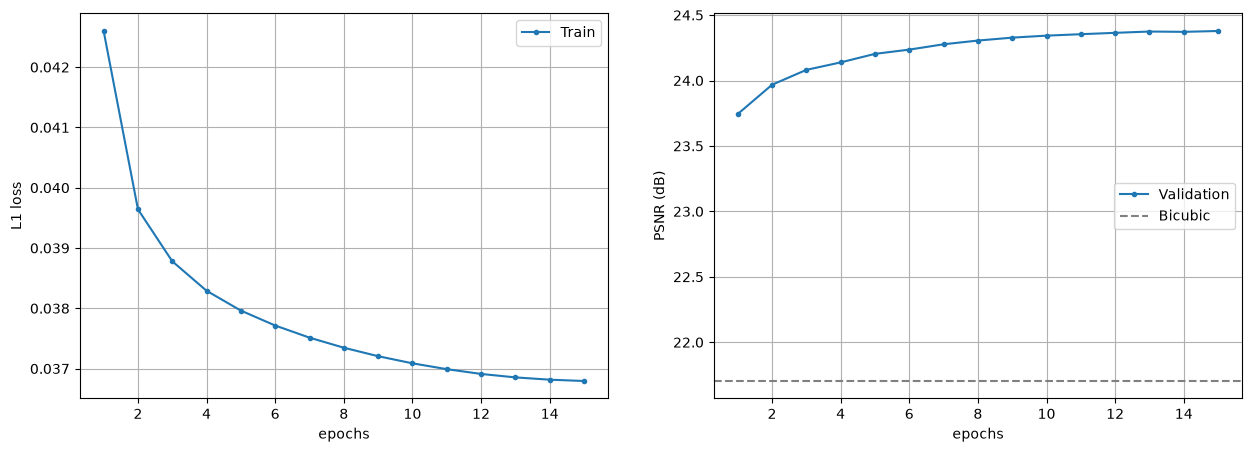

In [16]:
# Show training history
h = history
epochs_range = range(1, len(h['loss']) + 1)

plt.figure(figsize=(15, 5))
plt.subplot(121), plt.plot(epochs_range, h['loss'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('L1 loss')
plt.legend(['Train'])
plt.subplot(122), plt.plot(epochs_range, h['val_psnr'], '.-')
plt.axhline(val_bicubic, color='gray', linestyle='--')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('PSNR (dB)')
plt.legend(['Validation', 'Bicubic'])

print('Train loss      ', h['loss'][-1])
print('Validation PSNR ', max(h['val_psnr']), '(best epoch: %d)' % (np.argmax(h['val_psnr']) + 1))
print('Bicubic PSNR    ', val_bicubic)

Finally, compute the metrics of the trained generator on the test set and compare them with the baselines.

In [17]:
# Evaluate the trained generator on the test set
sr_l1 = model_upscale(generator, lr_test)
results['srresnet_l1'] = {'psnr': psnr(sr_l1, hr_test_u8).mean(),
                          'ssim': ssim(sr_l1, hr_test_u8).mean(),
                          'lpips': lpips_dist(sr_l1, hr_test_u8).mean()}

print('%-12s %10s %8s %8s' % ('', 'PSNR (dB)', 'SSIM', 'LPIPS'))
for name, r in results.items():
    print('%-12s %10.2f %8.4f %8.4f' % (name, r['psnr'], r['ssim'], r['lpips']))

              PSNR (dB)     SSIM    LPIPS
nearest           20.05   0.4977   0.5813
bilinear          20.93   0.5623   0.5498
bicubic           21.63   0.5881   0.5636
lanczos           21.71   0.5897   0.5718
srresnet_l1       24.30   0.7348   0.2291


The trained generator clearly beats all the baselines. On the test set, the PSNR goes from 21.71 dB (Lanczos, the best baseline) to 24.30 dB, the SSIM from 0.59 to 0.73 and the LPIPS drops from 0.55 (bilinear) to 0.23. A gain of 2.6 dB means that the mean squared error is almost halved.

Most of the improvement comes very early: the network is 2 dB above bicubic after the first epoch already. Then the validation PSNR keeps growing slowly and it is almost flat at the end (+0.01 dB in the last epoch), so training longer with this loss would not help much.

Note that the L1 loss has a weak point. Many different sharp faces shrink to the same 16×16 input, and the output with the lowest error is something like their average, i.e., a smooth face without fine textures (hair, skin, eyelashes). This is what the second stage is going to work on.

### Step 7: Fine-Tuning with the Perceptual and the Adversarial Loss (Stage 2)

The stage 1 generator is accurate, but its faces are smooth. In the second stage, we take a copy of it and continue the training with three losses at once:
* **Pixel loss** (L1, as before): keeps the colors and the overall structure faithful to the target.
* **Perceptual loss**: the L1 distance between the VGG-19 feature maps of the output and of the target. It rewards the right edges and textures instead of the right individual pixels.
* **Adversarial loss**: a second network, the discriminator, learns to tell the real faces from the generated ones, and the generator learns to fool it. This pushes the outputs towards sharp, realistic-looking faces.

This setup is known as SRGAN. We should expect the PSNR to drop a little compared with stage 1, while the faces get sharper and the LPIPS improves.

Let's start with the perceptual loss. The VGG-19 network (pretrained on ImageNet) is used as a fixed feature extractor, its weights are never trained. We take the features of five convolutional layers, before their ReLU activation.

In [18]:
class PerceptualLoss(nn.Module):
    # Layers of VGG-19 we take the features from (conv1_2, conv2_2, conv3_4, conv4_4, conv5_4) and their weights
    layer_weights = {2: 0.1, 7: 0.1, 16: 1.0, 25: 1.0, 34: 1.0}

    def __init__(self):
        super().__init__()
        # Pretrained VGG-19 (its weights go to the data folder as well), we only need the layers up to conv5_4
        vgg = torchvision.models.vgg19(weights=torchvision.models.VGG19_Weights.DEFAULT).features[:35]
        for layer in vgg:
            if isinstance(layer, nn.ReLU):
                layer.inplace = False    # an in-place ReLU would overwrite the features we want to keep
        # The feature extractor is not trained
        for p in vgg.parameters():
            p.requires_grad_(False)
        self.vgg = vgg.eval()
        # VGG expects the images normalized with the ImageNet mean and std
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def features(self, x):
        x = (x - self.mean)/self.std
        out = []
        for ii, layer in enumerate(self.vgg):
            x = layer(x)
            if ii in self.layer_weights:
                out.append(x)
        return out

    def forward(self, sr, hr):
        # The target does not need gradients
        with torch.no_grad():
            f_hr = self.features(hr)
        f_sr = self.features(sr)
        return sum(w*F.l1_loss(a, b) for w, a, b in zip(self.layer_weights.values(), f_sr, f_hr))

perceptual_loss = PerceptualLoss().to(device)

# Sanity check: the loss of the first test faces against themselves, the stage 1 output and the bicubic upscale
with torch.no_grad():
    hr = to_tensor(hr_test[:100])
    print('Identical:    %.3f' % perceptual_loss(hr, hr))
    print('Stage 1:      %.3f' % perceptual_loss(to_tensor(sr_l1[:100]), hr))
    print('Bicubic:      %.3f' % perceptual_loss(to_tensor(cv2_upscale(lr_test[:100], cv2.INTER_CUBIC)), hr))

Identical:    0.000
Stage 1:      14.207
Bicubic:      20.713


Now build the discriminator. It is a plain CNN with four blocks, each of them halves the resolution (128 → 64 → 32 → 16 → 8) and doubles the number of channels. Its output is not a single number, but an 8×8 map of real/fake scores, one for each region of the image.

Note the spectral normalization of the convolutions. It limits how fast the output of the discriminator can change, which makes the GAN training more stable.

In [19]:
class Discriminator(nn.Module):
    def __init__(self, base=64):
        super().__init__()
        sn = nn.utils.spectral_norm
        layers, c_in = [], 3
        for c_out in (base, 2*base, 4*base, 8*base):
            # The second convolution of each block halves the resolution (stride 2)
            layers += [sn(nn.Conv2d(c_in, c_out, 3, 1, 1)), nn.LeakyReLU(0.2, inplace=True),
                       sn(nn.Conv2d(c_out, c_out, 4, 2, 1)), nn.LeakyReLU(0.2, inplace=True)]
            c_in = c_out
        # One real/fake score per region
        layers.append(nn.Conv2d(c_in, 1, 3, 1, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        # Always in full precision, the spectral normalization is not reliable in 16-bit floats
        with torch.autocast(x.device.type, enabled=False):
            return self.net(x.float() - 0.5)

# Show the model
discriminator = Discriminator().to(device)
with torch.no_grad():
    scores = discriminator(to_tensor(hr_test[:6]))

print('Params: ', sum(p.numel() for p in discriminator.parameters()))
print('Input:  ', (6, 3, hr_size, hr_size))
print('Output: ', tuple(scores.shape))

Params:  7127105
Input:   (6, 3, 128, 128)
Output:  (6, 1, 8, 8)


Fine-tune the generator. Every training step has two parts:
1. **Discriminator update**: it sees the real HR faces (label 1) and the generated faces (label 0).
2. **Generator update**: the weights of the discriminator are frozen, and the generator is updated with the weighted sum of the three losses. Its adversarial loss is low when the discriminator takes the generated faces for the real ones.

As in the previous step, the weights are stored in the `models` folder and the training is skipped if the file is already there. This time we keep the weights of the last epoch, not of the best one: the PSNR is not what we optimize anymore.

In [20]:
epochs_gan = 10
learning_rate_gan = 1e-4
# Weights of the pixel, the perceptual and the adversarial loss
w_pixel, w_perceptual, w_adv = 1.0, 1.0, 0.1

path_gan = os.path.join(models_dir, 'generator_gan.pt')

def set_requires_grad(model, flag):
    for p in model.parameters():
        p.requires_grad_(flag)

def train_gan(model, model_d, epochs):
    steps = len(hr_train)//batch_size
    bce = nn.BCEWithLogitsLoss()
    optimizer_g = torch.optim.Adam(model.parameters(), lr=learning_rate_gan, betas=(0.9, 0.99))
    optimizer_d = torch.optim.Adam(model_d.parameters(), lr=learning_rate_gan, betas=(0.9, 0.99))
    scaler_g = torch.amp.GradScaler(device.type, enabled=use_amp)
    scaler_d = torch.amp.GradScaler(device.type, enabled=use_amp)
    history = {'pixel': [], 'perceptual': [], 'adv': [], 'd': [], 'val_psnr': []}

    for epoch in range(epochs):
        start = time()
        model.train()
        totals = np.zeros(4)
        for hr in batches(hr_train, batch_size):
            lr = degrade(hr)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                sr = model(lr)

            # Discriminator update: real -> 1, generated -> 0
            set_requires_grad(model_d, True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                # The generated faces are detached, this update must not change the generator
                d_real, d_fake = model_d(hr), model_d(sr.detach())
                loss_d = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
            optimizer_d.zero_grad(set_to_none=True)
            scaler_d.scale(loss_d).backward()
            scaler_d.step(optimizer_d)
            scaler_d.update()

            # Generator update: stay close to the target and fool the discriminator
            set_requires_grad(model_d, False)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                loss_pixel = F.l1_loss(sr, hr)
                loss_perceptual = perceptual_loss(sr, hr)
                d_out = model_d(sr)
                loss_adv = bce(d_out, torch.ones_like(d_out))
                loss_g = w_pixel*loss_pixel + w_perceptual*loss_perceptual + w_adv*loss_adv
            optimizer_g.zero_grad(set_to_none=True)
            scaler_g.scale(loss_g).backward()
            scaler_g.step(optimizer_g)
            scaler_g.update()

            totals += [loss_pixel.item(), loss_perceptual.item(), loss_adv.item(), loss_d.item()]

        # Validation
        val_psnr = validate(model)
        for key, value in zip(('pixel', 'perceptual', 'adv', 'd'), totals/steps):
            history[key].append(float(value))
        history['val_psnr'].append(val_psnr)
        print('Epoch %d/%d - %ds - pixel: %.4f - perceptual: %.3f - adv: %.3f - d: %.3f - val_psnr: %.2f' % (
            epoch+1, epochs, time() - start, history['pixel'][-1], history['perceptual'][-1],
            history['adv'][-1], history['d'][-1], val_psnr))
    return history

# Start from the stage 1 weights
generator_gan = copy.deepcopy(generator)

if os.path.exists(path_gan):
    # Load the trained model
    checkpoint = torch.load(path_gan, map_location=device)
    generator_gan.load_state_dict(checkpoint['model'])
    history_gan = checkpoint['history']
    print('Loaded', path_gan)
else:
    # Train the model
    start = time()
    history_gan = train_gan(generator_gan, discriminator, epochs_gan)
    print('Elapsed time', time() - start)
    torch.save({'model': generator_gan.state_dict(), 'history': history_gan}, path_gan)
    print('Saved', path_gan)

Loaded /home/anton/PycharmProjects/facecast/models/generator_gan.pt


Validation PSNR stage 1  24.378361099961555
Validation PSNR stage 2  23.11706918312675


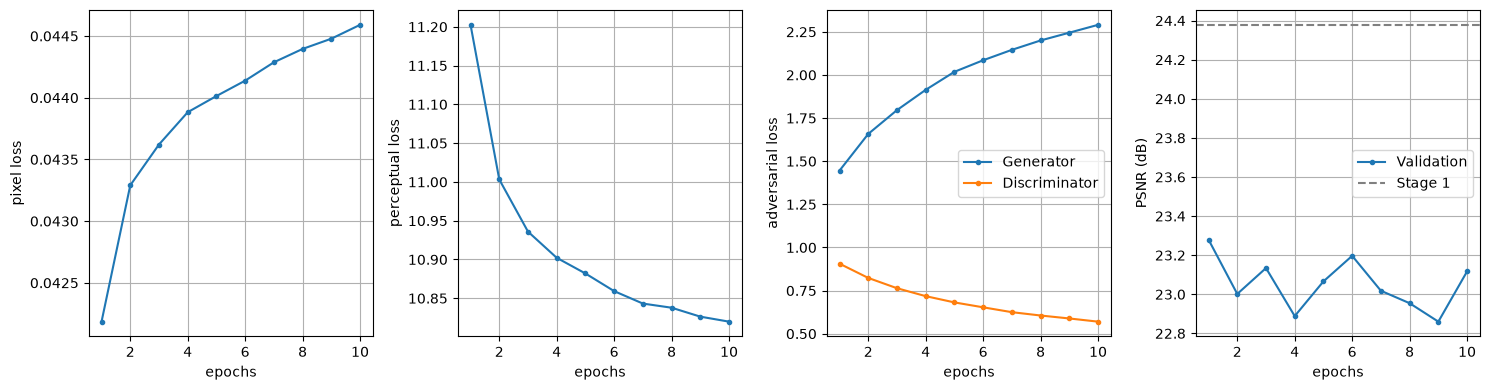

In [21]:
# Show training history
h = history_gan
epochs_range = range(1, len(h['pixel']) + 1)

plt.figure(figsize=(15, 4))
plt.subplot(141), plt.plot(epochs_range, h['pixel'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('pixel loss')
plt.subplot(142), plt.plot(epochs_range, h['perceptual'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('perceptual loss')
plt.subplot(143), plt.plot(epochs_range, h['adv'], '.-', epochs_range, h['d'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('adversarial loss')
plt.legend(['Generator', 'Discriminator'])
plt.subplot(144), plt.plot(epochs_range, h['val_psnr'], '.-')
plt.axhline(max(history['val_psnr']), color='gray', linestyle='--')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('PSNR (dB)')
plt.legend(['Validation', 'Stage 1'])
plt.tight_layout()

print('Validation PSNR stage 1 ', max(history['val_psnr']))
print('Validation PSNR stage 2 ', h['val_psnr'][-1])

Compute the metrics of the fine-tuned generator on the test set and compare them with the stage 1 generator and the baselines.

In [22]:
# Evaluate the fine-tuned generator on the test set
sr_gan = model_upscale(generator_gan, lr_test)
results['srgan'] = {'psnr': psnr(sr_gan, hr_test_u8).mean(),
                    'ssim': ssim(sr_gan, hr_test_u8).mean(),
                    'lpips': lpips_dist(sr_gan, hr_test_u8).mean()}

print('%-12s %10s %8s %8s' % ('', 'PSNR (dB)', 'SSIM', 'LPIPS'))
for name, r in results.items():
    print('%-12s %10.2f %8.4f %8.4f' % (name, r['psnr'], r['ssim'], r['lpips']))

              PSNR (dB)     SSIM    LPIPS
nearest           20.05   0.4977   0.5813
bilinear          20.93   0.5623   0.5498
bicubic           21.63   0.5881   0.5636
lanczos           21.71   0.5897   0.5718
srresnet_l1       24.30   0.7348   0.2291
srgan             23.06   0.6792   0.1094


The result is the trade-off we expected. Compared with stage 1, the fine-tuned generator loses 1.2 dB of PSNR on the test set (24.30 → 23.06 dB) and some SSIM (0.73 → 0.68), but its LPIPS is two times better (0.229 → 0.109). It is still clearly better than all the baselines in all three metrics.

The training history shows how it happens. The perceptual loss goes down, while the pixel loss goes slightly up: the generator gives up a bit of the pixel accuracy in exchange for the textures. This is known as the perception-distortion trade-off, an image can not be the most accurate one and the most realistic one at the same time.

Three more things to note:
* The loss of the discriminator keeps going down (0.91 → 0.57) and the adversarial loss of the generator keeps going up (1.45 → 2.29), i.e., the discriminator is winning. A better discriminator or a regularization of this one is the thing to try next.
* The validation PSNR jumps up and down between the epochs (22.9 - 23.3 dB), which is typical for a GAN. So a difference of a few tenths of dB between two runs does not mean much.
* Training longer did not help much. An earlier run with 4 epochs instead of 10 gave 22.77 dB, an SSIM of 0.671 and an LPIPS of 0.106 on the same test faces. So the extra 6 epochs brought +0.3 dB of PSNR and a slightly worse LPIPS, which is within the jumps mentioned above. Most of the effect of the fine-tuning comes in the first epoch.

### Step 8: Modification: Relativistic Loss and U-Net Discriminator

In the previous step, the discriminator was winning: its loss kept going down while the adversarial loss of the generator kept going up. Training longer did not help either. So the modification is on the side of the discriminator, and it has two parts:

* **U-Net discriminator.** The discriminator from Step 7 shrinks the face to an 8×8 map of scores, so each score judges a large region and the generator only learns *roughly where* something looks fake. The U-Net discriminator goes down (128 → 64 → 32 → 16) and then up again (16 → 32 → 64 → 128), with skip connections between the layers of the same size. Its output is a 128×128 map, i.e., one real/fake score for **every pixel**. The way down tells it what the whole face looks like, the way up and the skip connections tell it exactly where the details are.
* **Relativistic loss.** So far, the discriminator has judged each image on its own: "is this face real?". The relativistic discriminator answers a different question: "is this real face *more realistic* than the generated ones (on average)?". The generator is then trained to turn this around, to make its faces look more realistic than the real ones. As a result, the generator gets gradients from the real faces too, not only from its own outputs.

Everything else stays the same as in Step 7: we start from the stage 1 weights and we use the same pixel and perceptual loss, the same loss weights and the same learning rate. The only other difference is the number of epochs: 4 instead of 10. The U-Net discriminator works at the full resolution, so one epoch takes about three times longer (about 590 s instead of 200 s). With 4 epochs, the modified run costs about the same time as the base run with 10 epochs (39 vs. 34 minutes).

Note that we change the two things at once (the discriminator and its loss), so we can not tell which one of them is responsible for the difference.

In [23]:
class UNetDiscriminator(nn.Module):
    def __init__(self, base=64):
        super().__init__()
        sn = nn.utils.spectral_norm
        # The way down: every convolution halves the resolution (stride 2)
        self.conv0 = nn.Conv2d(3, base, 3, 1, 1)
        self.down1 = sn(nn.Conv2d(base, 2*base, 4, 2, 1))
        self.down2 = sn(nn.Conv2d(2*base, 4*base, 4, 2, 1))
        self.down3 = sn(nn.Conv2d(4*base, 8*base, 4, 2, 1))
        # The way up: the resolution is doubled before every convolution
        self.up1 = sn(nn.Conv2d(8*base, 4*base, 3, 1, 1))
        self.up2 = sn(nn.Conv2d(4*base, 2*base, 3, 1, 1))
        self.up3 = sn(nn.Conv2d(2*base, base, 3, 1, 1))
        # Two more convolutions and one real/fake score per pixel
        self.conv1 = sn(nn.Conv2d(base, base, 3, 1, 1))
        self.conv2 = sn(nn.Conv2d(base, base, 3, 1, 1))
        self.conv3 = nn.Conv2d(base, 1, 3, 1, 1)

    def forward(self, x):
        # Always in full precision, as the discriminator in Step 7
        with torch.autocast(x.device.type, enabled=False):
            act = lambda t: F.leaky_relu(t, 0.2)
            up = lambda t: F.interpolate(t, scale_factor=2, mode='bilinear', align_corners=False)
            # The way down
            x0 = act(self.conv0(x.float() - 0.5))
            x1 = act(self.down1(x0))
            x2 = act(self.down2(x1))
            x3 = act(self.down3(x2))
            # The way up, with the skip connections
            x = act(self.up1(up(x3))) + x2
            x = act(self.up2(up(x))) + x1
            x = act(self.up3(up(x))) + x0
            x = act(self.conv2(act(self.conv1(x))))
            return self.conv3(x)

# Show the model
discriminator_unet = UNetDiscriminator().to(device)
with torch.no_grad():
    scores = discriminator_unet(to_tensor(hr_test[:6]))

print('Params: ', sum(p.numel() for p in discriminator_unet.parameters()))
print('Input:  ', (6, 3, hr_size, hr_size))
print('Output: ', tuple(scores.shape))

Params:  4378369
Input:   (6, 3, 128, 128)
Output:  (6, 1, 128, 128)


Fine-tune a second copy of the stage 1 generator. The training loop is the same as in Step 7, only the adversarial losses are different. They do not look at the scores themselves, but at the differences:
* how much more real a real face looks than the average generated face (`real_vs_fake`),
* how much more real a generated face looks than the average real face (`fake_vs_real`).

The discriminator wants the first one high and the second one low, the generator wants the opposite.

In [24]:
epochs_unet = 4

path_unet = os.path.join(models_dir, 'generator_gan_unet.pt')

def train_gan_relativistic(model, model_d, epochs):
    steps = len(hr_train)//batch_size
    bce = nn.BCEWithLogitsLoss()
    optimizer_g = torch.optim.Adam(model.parameters(), lr=learning_rate_gan, betas=(0.9, 0.99))
    optimizer_d = torch.optim.Adam(model_d.parameters(), lr=learning_rate_gan, betas=(0.9, 0.99))
    scaler_g = torch.amp.GradScaler(device.type, enabled=use_amp)
    scaler_d = torch.amp.GradScaler(device.type, enabled=use_amp)
    history = {'pixel': [], 'perceptual': [], 'adv': [], 'd': [], 'val_psnr': []}

    for epoch in range(epochs):
        start = time()
        model.train()
        totals = np.zeros(4)
        for hr in batches(hr_train, batch_size):
            lr = degrade(hr)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                sr = model(lr)

            # Discriminator update: the real faces should look more real than the generated ones
            set_requires_grad(model_d, True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                d_real, d_fake = model_d(hr), model_d(sr.detach())
                real_vs_fake = d_real - d_fake.mean()
                fake_vs_real = d_fake - d_real.mean()
                loss_d = bce(real_vs_fake, torch.ones_like(real_vs_fake)) + bce(fake_vs_real, torch.zeros_like(fake_vs_real))
            optimizer_d.zero_grad(set_to_none=True)
            scaler_d.scale(loss_d).backward()
            scaler_d.step(optimizer_d)
            scaler_d.update()

            # Generator update: stay close to the target and turn the comparison around
            set_requires_grad(model_d, False)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                loss_pixel = F.l1_loss(sr, hr)
                loss_perceptual = perceptual_loss(sr, hr)
                # The real faces are only a reference here, they do not need gradients
                with torch.no_grad():
                    d_real = model_d(hr)
                d_fake = model_d(sr)
                real_vs_fake = d_real - d_fake.mean()
                fake_vs_real = d_fake - d_real.mean()
                loss_adv = (bce(real_vs_fake, torch.zeros_like(real_vs_fake)) + bce(fake_vs_real, torch.ones_like(fake_vs_real)))/2
                loss_g = w_pixel*loss_pixel + w_perceptual*loss_perceptual + w_adv*loss_adv
            optimizer_g.zero_grad(set_to_none=True)
            scaler_g.scale(loss_g).backward()
            scaler_g.step(optimizer_g)
            scaler_g.update()

            totals += [loss_pixel.item(), loss_perceptual.item(), loss_adv.item(), loss_d.item()]

        # Validation
        val_psnr = validate(model)
        for key, value in zip(('pixel', 'perceptual', 'adv', 'd'), totals/steps):
            history[key].append(float(value))
        history['val_psnr'].append(val_psnr)
        print('Epoch %d/%d - %ds - pixel: %.4f - perceptual: %.3f - adv: %.3f - d: %.3f - val_psnr: %.2f' % (
            epoch+1, epochs, time() - start, history['pixel'][-1], history['perceptual'][-1],
            history['adv'][-1], history['d'][-1], val_psnr))
    return history

# Start from the stage 1 weights again
generator_unet = copy.deepcopy(generator)

if os.path.exists(path_unet):
    # Load the trained model
    checkpoint = torch.load(path_unet, map_location=device)
    generator_unet.load_state_dict(checkpoint['model'])
    history_unet = checkpoint['history']
    print('Loaded', path_unet)
else:
    # Train the model
    start = time()
    history_unet = train_gan_relativistic(generator_unet, discriminator_unet, epochs_unet)
    print('Elapsed time', time() - start)
    torch.save({'model': generator_unet.state_dict(), 'history': history_unet}, path_unet)
    print('Saved', path_unet)

Epoch 1/4 - 601s - pixel: 0.0423 - perceptual: 11.164 - adv: 4.647 - d: 0.693 - val_psnr: 23.11
Epoch 2/4 - 586s - pixel: 0.0432 - perceptual: 10.991 - adv: 7.971 - d: 0.458 - val_psnr: 23.11
Epoch 3/4 - 587s - pixel: 0.0436 - perceptual: 10.916 - adv: 9.214 - d: 0.447 - val_psnr: 23.15
Epoch 4/4 - 588s - pixel: 0.0437 - perceptual: 10.852 - adv: 9.256 - d: 0.457 - val_psnr: 22.91
Elapsed time 2363.6515736579895
Saved /home/anton/PycharmProjects/facecast/models/generator_gan_unet.pt


Validation PSNR base      23.11706918312675
Validation PSNR modified  22.910092789529195


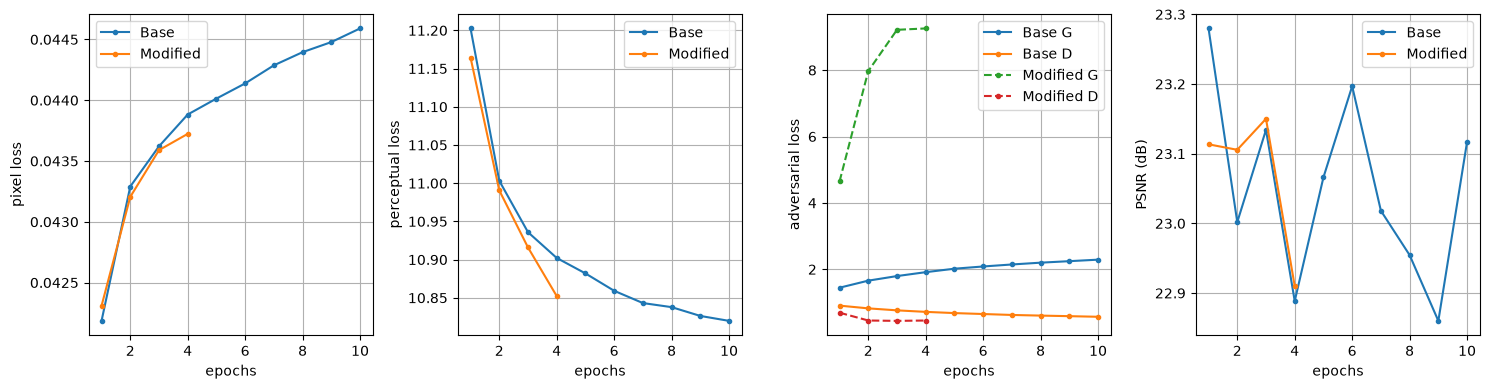

In [25]:
# Compare the training history of the base and the modified stage 2
h1, h2 = history_gan, history_unet
e1, e2 = range(1, len(h1['pixel']) + 1), range(1, len(h2['pixel']) + 1)

plt.figure(figsize=(15, 4))
plt.subplot(141), plt.plot(e1, h1['pixel'], '.-', e2, h2['pixel'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('pixel loss')
plt.legend(['Base', 'Modified'])
plt.subplot(142), plt.plot(e1, h1['perceptual'], '.-', e2, h2['perceptual'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('perceptual loss')
plt.legend(['Base', 'Modified'])
plt.subplot(143), plt.plot(e1, h1['adv'], '.-', e1, h1['d'], '.-')
plt.plot(e2, h2['adv'], '.--', e2, h2['d'], '.--')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('adversarial loss')
plt.legend(['Base G', 'Base D', 'Modified G', 'Modified D'])
plt.subplot(144), plt.plot(e1, h1['val_psnr'], '.-', e2, h2['val_psnr'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('PSNR (dB)')
plt.legend(['Base', 'Modified'])
plt.tight_layout()

print('Validation PSNR base     ', h1['val_psnr'][-1])
print('Validation PSNR modified ', h2['val_psnr'][-1])

In [26]:
# Compare the models on the test set
sr_unet = model_upscale(generator_unet, lr_test)
results['srgan_unet'] = {'psnr': psnr(sr_unet, hr_test_u8).mean(),
                         'ssim': ssim(sr_unet, hr_test_u8).mean(),
                         'lpips': lpips_dist(sr_unet, hr_test_u8).mean()}

print('%-12s %10s %8s %8s' % ('', 'PSNR (dB)', 'SSIM', 'LPIPS'))
for name, r in results.items():
    print('%-12s %10.2f %8.4f %8.4f' % (name, r['psnr'], r['ssim'], r['lpips']))

              PSNR (dB)     SSIM    LPIPS
nearest           20.05   0.4977   0.5813
bilinear          20.93   0.5623   0.5498
bicubic           21.63   0.5881   0.5636
lanczos           21.71   0.5897   0.5718
srresnet_l1       24.30   0.7348   0.2291
srgan             23.06   0.6792   0.1094
srgan_unet        22.86   0.6752   0.1065


Does the modification help? Compare the modified stage 2 (4 epochs) with the base stage 2 (10 epochs):

| | PSNR (dB) | SSIM | LPIPS |
|---|---|---|---|
| Base (10 epochs) | 23.06 | 0.6792 | 0.1094 |
| Modified (4 epochs) | 22.86 | 0.6752 | 0.1065 |

The two are practically the same. The modified one has a slightly better LPIPS (0.107 vs. 0.109) and a slightly worse PSNR (−0.2 dB), but both differences are smaller than the jumps between two epochs of the same run. So the modified stage 2 gets to the same quality in 4 epochs instead of 10, but it does not get there faster on the clock, because its epochs are three times longer.

The training history tells a bit more:
* **The perceptual loss goes down faster.** After 4 epochs, it is at 10.85. The base run needed about 6 - 7 epochs to get there.
* **The discriminator is winning even more than before.** The adversarial loss of the generator goes from 4.6 to 9.3 and then it stays there, while the loss of the discriminator stays at about 0.45. The two losses are defined differently than in Step 7, so the values can not be compared directly, but the direction is clear. With a score for every pixel, the discriminator finds the generated faces easily, and the generator can not keep up.

So the modification did not solve the problem it was meant to solve. The next thing to try is to give the generator a better chance, e.g., a lower learning rate of the discriminator or a higher weight of the adversarial loss.

### Step 9: Evaluation

In this step, we put everything together: the final table with all the methods, the visual comparison and the failure cases. For the evaluation, we use the test split, i.e., faces of people the networks have never seen.

The quality metrics are already computed, the only thing missing is the speed. We measure the average time needed to upscale one image. Note that the baselines run on the CPU, one image at a time, while the networks run on the GPU in batches of 100 images.

In [27]:
def measure_time(upscale):
    # Warm-up, so the one-off start-up costs are not measured
    upscale(lr_test[:100])
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time()
    upscale(lr_test)
    # Wait until the GPU is really done
    if device.type == 'cuda':
        torch.cuda.synchronize()
    # Milliseconds per image
    return 1000*(time() - start)/len(lr_test)

# Measure the time of each method
for name, interpolation in baselines.items():
    results[name]['ms'] = measure_time(lambda x: cv2_upscale(x, interpolation))
results['srresnet_l1']['ms'] = measure_time(lambda x: model_upscale(generator, x))
results['srgan']['ms'] = measure_time(lambda x: model_upscale(generator_gan, x))
results['srgan_unet']['ms'] = measure_time(lambda x: model_upscale(generator_unet, x))

# The final table (higher is better for PSNR and SSIM, lower is better for LPIPS)
table = pd.DataFrame(results).T
table.columns = ['PSNR (dB)', 'SSIM', 'LPIPS', 'ms / image']
print(len(lr_test), 'test faces, %dx%d -> %dx%d' % (lr_size, lr_size, hr_size, hr_size))
table.round(4)

2000 test faces, 16x16 -> 128x128


,PSNR (dB),SSIM,LPIPS,ms / image
nearest,20.0512,0.4977,0.5813,0.0176
bilinear,20.9280,0.5623,0.5498,0.0187
bicubic,21.6262,0.5881,0.5636,0.0179
lanczos,21.7113,0.5897,0.5718,0.1152
srresnet_l1,24.3042,0.7348,0.2291,0.1177
srgan,23.0634,0.6792,0.1094,0.1159
srgan_unet,22.8635,0.6752,0.1065,0.1154


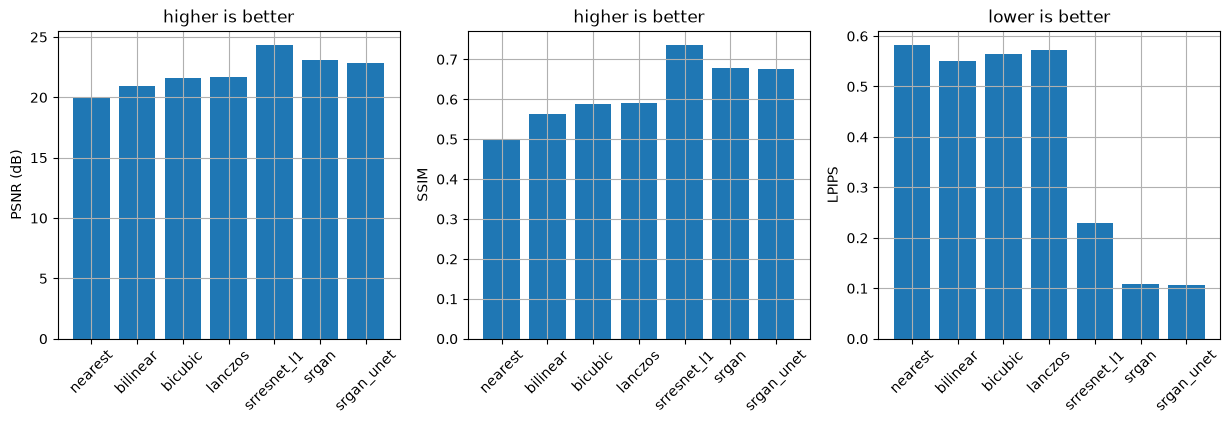

In [28]:
# Show the quality metrics as bar plots
plt.figure(figsize=(15, 4))
for ii, col in enumerate(['PSNR (dB)', 'SSIM', 'LPIPS']):
    plt.subplot(1,3,ii+1), plt.bar(list(table.index), table[col])
    plt.grid(True), plt.ylabel(col), plt.xticks(rotation=45)
    plt.title('lower is better' if col == 'LPIPS' else 'higher is better')

The numbers are only a part of the story, so let's look at the faces. Every row is one test face: the LR input, the bicubic baseline, the three generators and the original.

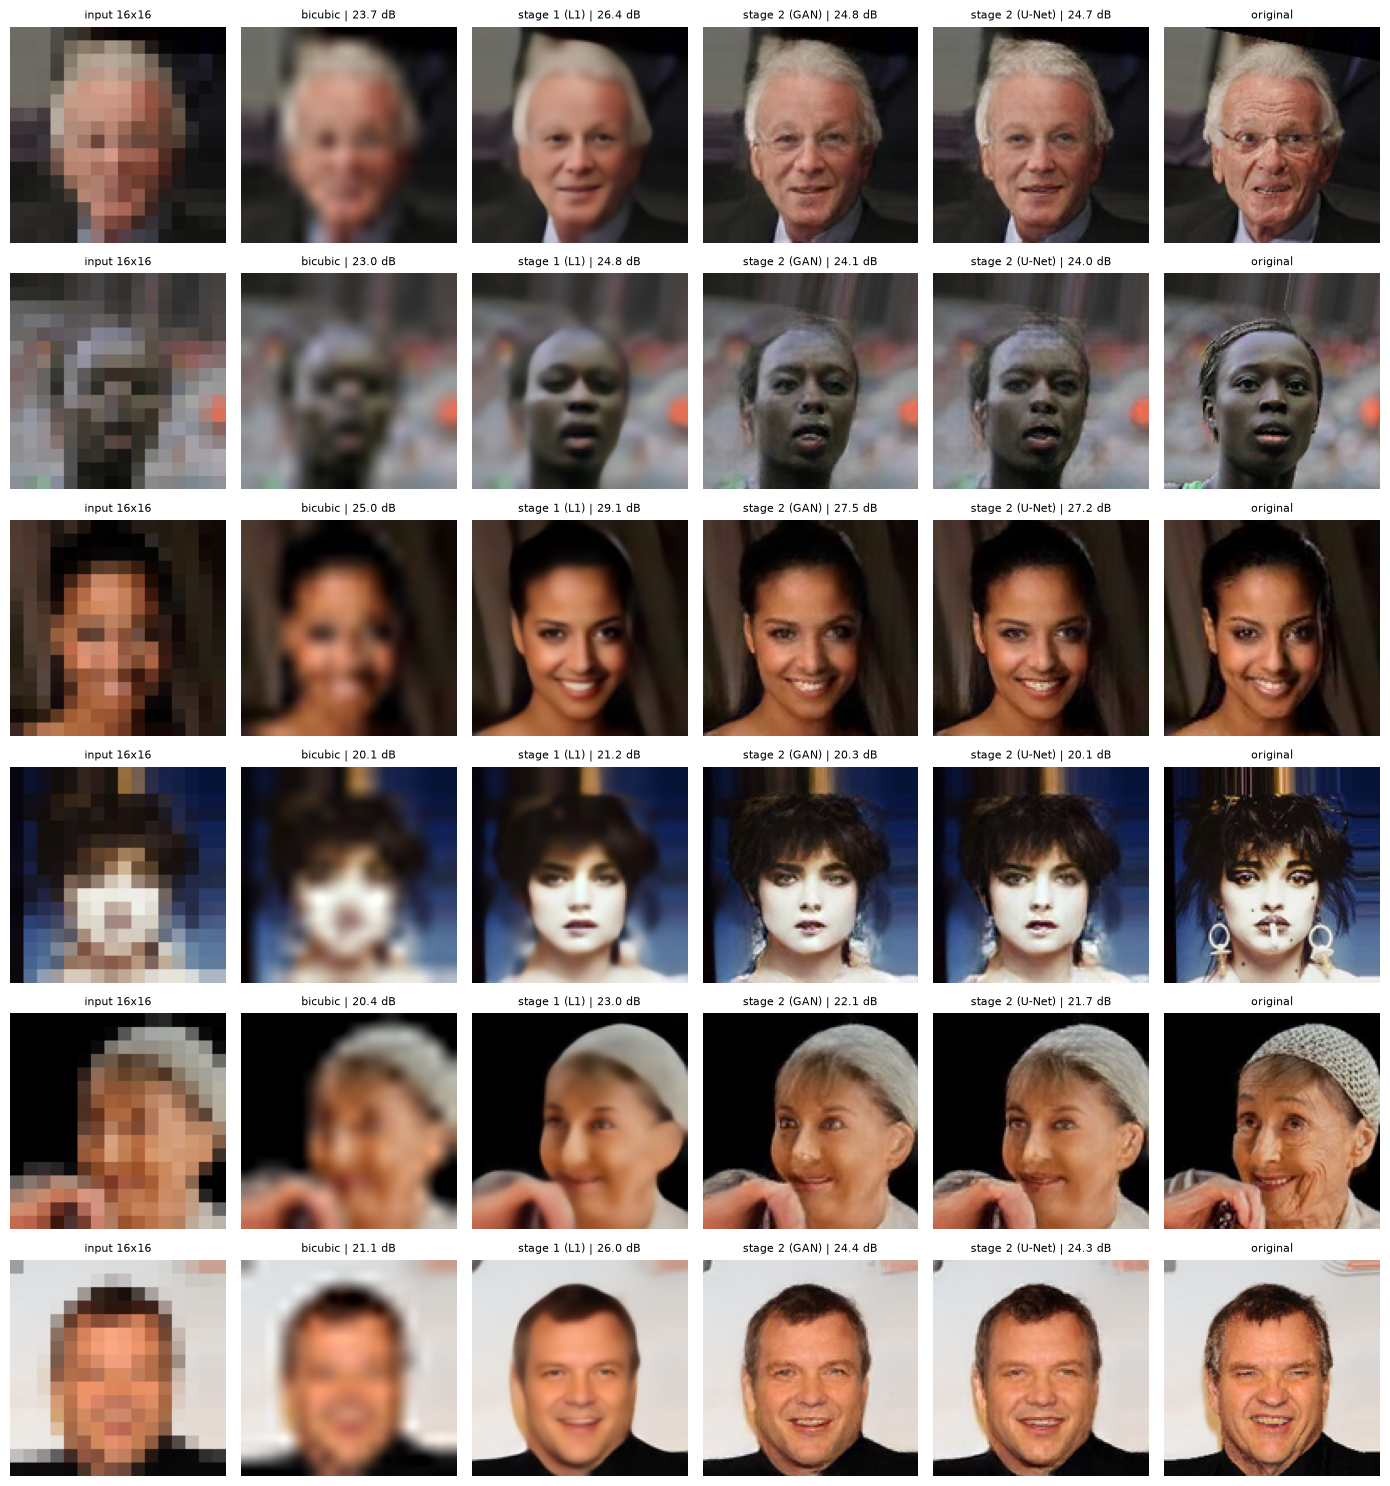

In [29]:
sr_bicubic = cv2_upscale(lr_test, cv2.INTER_CUBIC)

def show_comparison(indices):
    # One row per face, one column per method
    columns = {'input %dx%d' % (lr_size, lr_size): cv2_upscale(lr_test, cv2.INTER_NEAREST), 'bicubic': sr_bicubic,
               'stage 1 (L1)': sr_l1, 'stage 2 (GAN)': sr_gan,
               'stage 2 (U-Net)': sr_unet, 'original': hr_test_u8}
    rows = len(indices)
    plt.figure(figsize=(14, 2.5*rows))
    for ii, idx in enumerate(indices):
        for jj, (name, images) in enumerate(columns.items()):
            plt.subplot(rows,len(columns),ii*len(columns)+jj+1), plt.imshow(images[idx])
            plt.axis('off')
            # The PSNR of this face (for the upscaled images only)
            if 0 < jj < len(columns) - 1:
                name += ' | %.1f dB' % psnr(images[idx:idx+1], hr_test_u8[idx:idx+1])[0]
            plt.title(name, fontsize=8)
    plt.tight_layout()

# Show random test samples
show_comparison(np.random.choice(len(hr_test), 6, replace=False))

Where does it fail? Let us see the test faces with the lowest PSNR of the stage 1 generator.

PSNR of the stage 1 generator: mean 24.30 dB, min 16.98 dB, max 34.37 dB


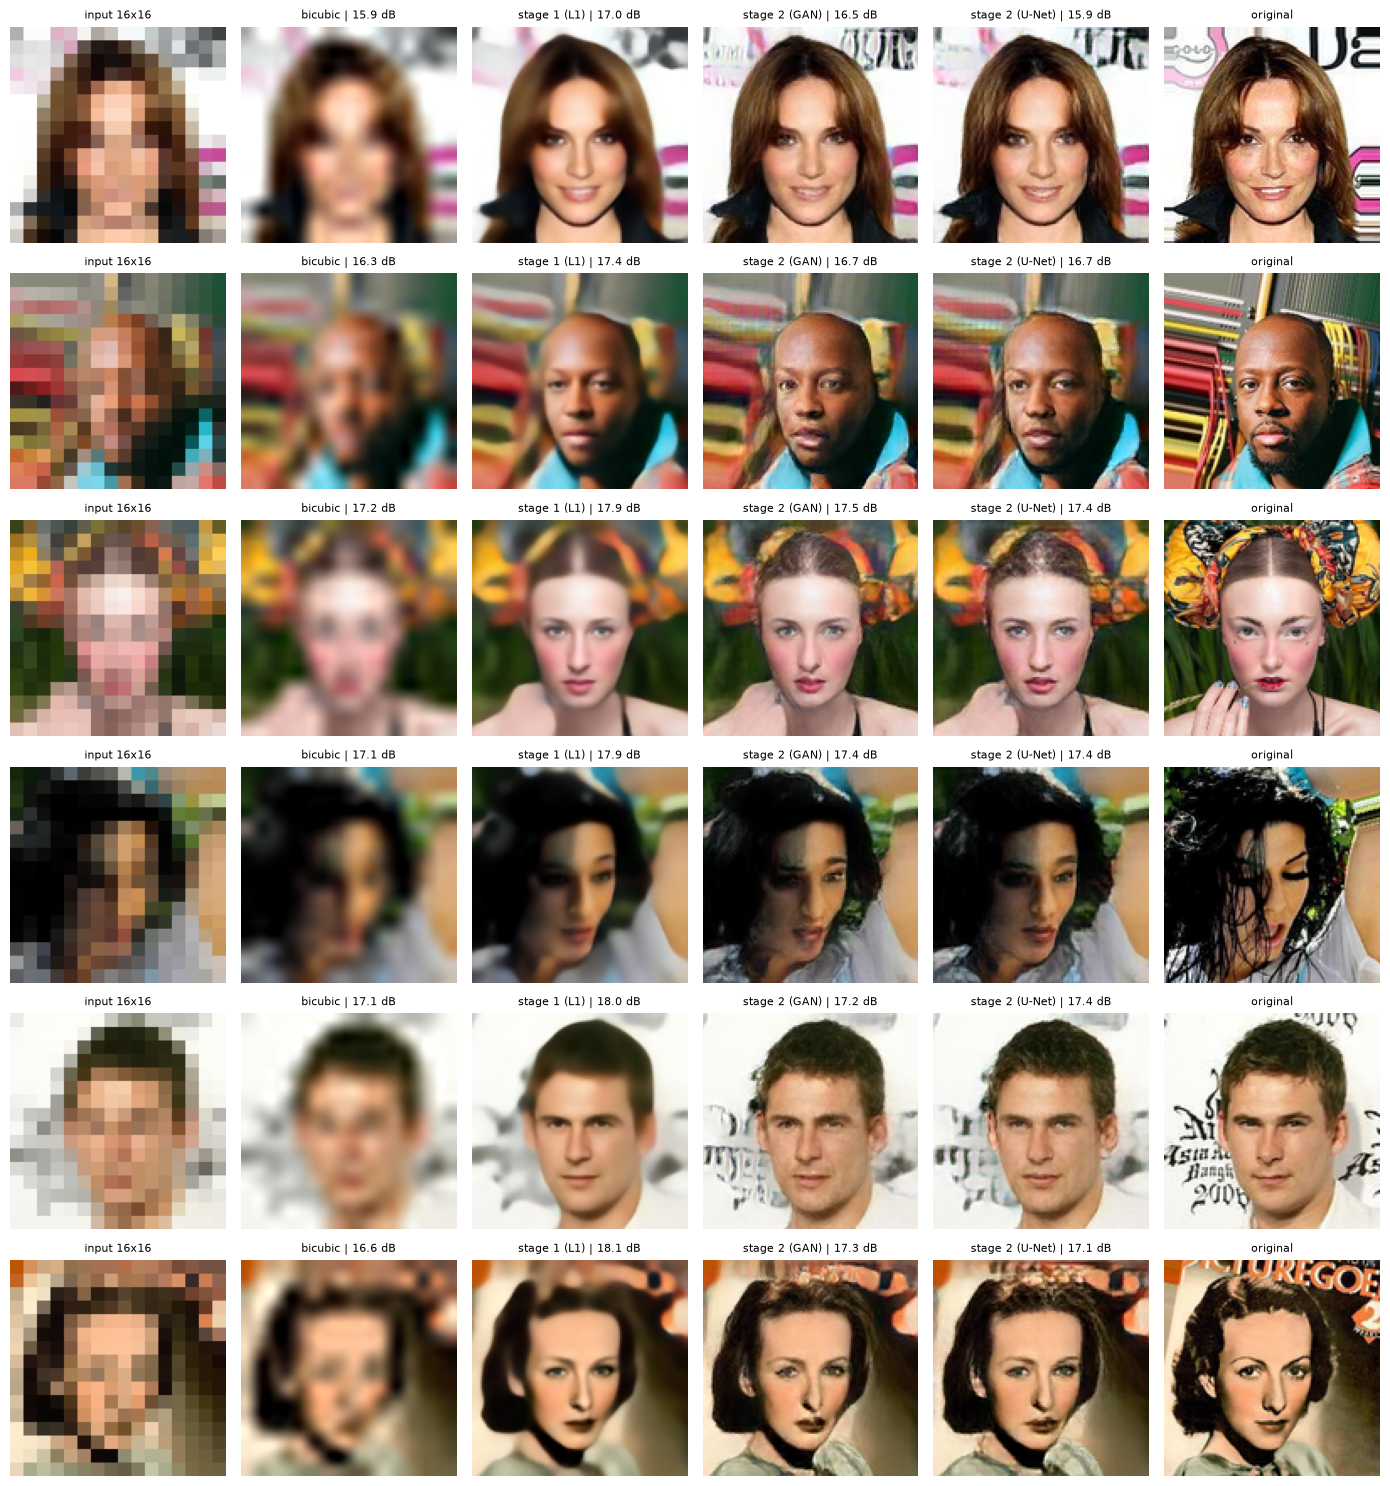

In [30]:
# Find the worst test samples
psnr_l1 = psnr(sr_l1, hr_test_u8)
worst = np.argsort(psnr_l1)[:6]

print('PSNR of the stage 1 generator: mean %.2f dB, min %.2f dB, max %.2f dB' % (psnr_l1.mean(), psnr_l1.min(), psnr_l1.max()))
show_comparison(worst)

### Results

* **All three generators beat the interpolation by a wide margin.** The best baseline (Lanczos) reaches 21.71 dB, the stage 1 generator 24.30 dB, the base stage 2 generator 23.06 dB and the modified one 22.86 dB. The same holds for the SSIM and the LPIPS.
* **Stage 1 is the most accurate, stage 2 is the most realistic.** Stage 1 wins the PSNR and the SSIM, but its faces are smooth, as if they were slightly out of focus. Stage 2 loses 1.2 - 1.4 dB, but it brings back the textures (hair, teeth, eyebrows) and its LPIPS is two times better (0.11 vs. 0.23). Which one is "better" depends on what we need: the smallest error or the most natural look.
* **The two versions of stage 2 are hard to tell apart.** The metrics of the base one (10 epochs) and the modified one (U-Net discriminator and relativistic loss, 4 epochs) differ by 0.2 dB and 0.003 of LPIPS, and so do the faces: the same details in the same places, with small differences in the hair and the wrinkles.
* **The details are invented, not recovered.** Compare the stage 2 faces with the originals: the eyes, the teeth and the hair look plausible, but they are not the same as in the original (e.g., the glasses are gone or only hinted at). The 16×16 input simply does not contain them. Therefore, the output must never be used to identify a person.
* **Where it fails.** The faces with the lowest PSNR (17 - 18 dB) are not really bad faces. They have a busy background (logos and text behind the person, a magazine cover, colorful cables), an unusual headwear (a patterned scarf) or wet hair and a strong shadow over the face. The network has learned faces, not letters or patterns, so it smears them. The GAN makes it look sharper, but it invents scribbles where the text was.
* **Speed.** All three generators need about 0.12 ms per image on the GPU, which is as fast as the Lanczos interpolation on the CPU. Note that they have the same architecture, so their time is the same.

A few limitations to keep in mind:
* The LR inputs are clean block averages. Real low-resolution photos also contain blur, noise and JPEG artifacts, so the results on them will be worse.
* CelebA consists of photos of celebrities, mostly frontal and well lit, and the network inherits this bias.
* The test set is a random subset (821 of the 1000 test people), but the validation set is still the first 2000 faces of its split, which is sorted by the person. It is only used to watch the training, so it matters less.

### Step 10: Demo on Your Own Image

Finally, try the generators on a photo that does not come from CelebA. The `demo` function does the whole pipeline: it crops the image to a square and resizes it to 128×128 (the same preprocessing as in Step 2), degrades it to 16×16 and restores it with the bicubic baseline and with all three generators. Because we have the original, it also prints the metrics.

If you only have a tiny image and no original, use `already_low_res=True`. Then the file itself is taken as the LR input (it is resized to 16×16 if needed) and there is nothing to compare with.

Note that the networks were trained on aligned CelebA faces, so the photo should be a roughly centered, front-facing face.

                  PSNR (dB)     SSIM    LPIPS
bicubic               23.76   0.6636   0.5187
stage 1 (L1)          27.06   0.7910   0.1754
stage 2 (GAN)         25.67   0.7324   0.0654
stage 2 (U-Net)       25.45   0.7343   0.0783


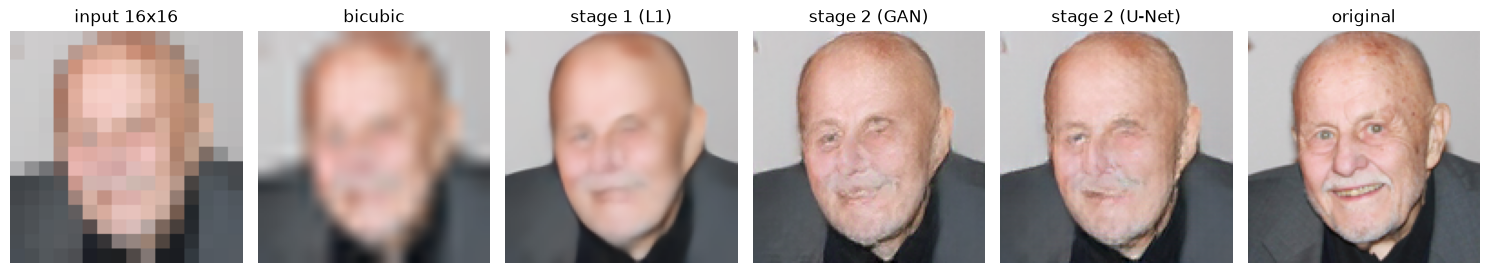

In [31]:
def demo(path, already_low_res=False):
    img = Image.open(path).convert('RGB')
    if already_low_res:
        # The file itself is the LR input
        lr_u8 = np.asarray(img.resize((lr_size, lr_size), Image.BOX), dtype=np.uint8)[None]
        hr_u8 = None
    else:
        # Preprocess the image as the CelebA faces and degrade it
        hr_u8 = preprocess(img)[None]
        lr_u8 = to_u8(degrade(to_tensor(hr_u8)))

    # Upscale the LR input with each method
    columns = {'input %dx%d' % (lr_size, lr_size): cv2_upscale(lr_u8, cv2.INTER_NEAREST),
               'bicubic': cv2_upscale(lr_u8, cv2.INTER_CUBIC),
               'stage 1 (L1)': model_upscale(generator, lr_u8),
               'stage 2 (GAN)': model_upscale(generator_gan, lr_u8),
               'stage 2 (U-Net)': model_upscale(generator_unet, lr_u8)}

    if hr_u8 is not None:
        # Compute the metrics against the original
        print('%-16s %10s %8s %8s' % ('', 'PSNR (dB)', 'SSIM', 'LPIPS'))
        for name in list(columns)[1:]:
            sr = columns[name]
            print('%-16s %10.2f %8.4f %8.4f' % (name, psnr(sr, hr_u8)[0], ssim(sr, hr_u8)[0], lpips_dist(sr, hr_u8)[0]))
        columns['original'] = hr_u8

    # Show the results
    plt.figure(figsize=(15, 3.5))
    for ii, (name, images) in enumerate(columns.items()):
        plt.subplot(1,len(columns),ii+1), plt.imshow(images[0])
        plt.title(name), plt.axis('off')
    plt.tight_layout()

# Try it on a photo from the data folder
demo(os.path.join(data_dir, 'Ivan_Ruller_2016.jpg'))

The metrics follow the same pattern as on the test set: stage 1 has the best PSNR (27.06 dB vs. 23.76 dB of bicubic) and stage 2 the best LPIPS (0.065 for the base one, 0.078 for the modified one). They are even better than the test averages, mostly because the plain background is easy to restore.

But the picture shows what the numbers hide. The shape of the head, the ear, the beard and the jacket are restored well. The eyes and the mouth are not: stage 1 leaves them blurred, and both versions of stage 2 draw the eyes half-closed and keep only a hint of the smile. They also draw the wrinkles in places where they find them plausible, not where they really are. So the result looks like an older man from afar, but more like something an AI would draw instead in 1725. The U-Net discriminator did not change this.

There are two reasons for this. The face fills more of the frame than the CelebA faces do, so the eyes and the mouth are not where the network expects them. And CelebA consists mostly of young celebrities, there are not many faces like this one to learn from. This is the dataset bias from the previous step in practice.